# Lab 8 · Chuỗi thời gian: quý, cửa sổ trượt và so cùng kỳ

**Lập trình xử lý dữ liệu (LTXLDL) · 2627-1 · Giờ thực hành · Bài 8**

> 💡 File → **Save a copy in Drive** trước khi sửa.

Notebook Bài 8 làm việc theo **tháng**. Lab này chuyển sang hai độ phân giải khác:
**ngày** (cửa sổ trượt 7 ngày) và **quý**, sau đó tính phép so cùng kỳ.

**Mục tiêu bài lab**

1. Cắt lát thời gian bằng chuỗi (`.loc["2019"]`) và đối chiếu với con số đã biết.
2. Tổng hợp theo quý (`resample`); nhận diện và loại kỳ chưa trọn ở cấp quý.
3. Làm mượt chuỗi ngày bằng cửa sổ trượt (`rolling`) và đọc điểm cao/thấp.
4. Tính so với cùng kỳ năm trước và phân biệt với so kỳ liền trước.

Phiên bản đề: `time-series-v1` (25/09/2026). Lưu đúng tên **`lab-08.ipynb`**.

## Cách làm và nộp bài

- Phần khởi động (Bài 1–2) và các bài có hướng dẫn: nên **tự gõ, không dùng AI** — các bài kiểm tra
  định kỳ 🚫 đóng ở giờ lý thuyết đánh giá các kỹ năng này. Bài tự làm cuối lab được gắn nhãn ✅ mở:
  được dùng AI, kèm trách nhiệm khai báo theo chính sách AI của môn.
- Ghi dự đoán trước khi chạy; điền thân hàm TODO và phần trả lời Markdown.
- Giữ tên hàm, tham số, cell ID và metadata; viết helper/import thêm trong chính cell bài làm.
  Grader chỉ chạy cell câu đó với input riêng, không phụ thuộc biến `rv`, `r`, `quy`, `SNAPSHOT`… ở cell khác.
  `pd` và `np` được cung cấp sẵn khi chấm.
- Public checks chỉ là ví dụ tự kiểm tra trên dữ liệu giả lập; test ẩn dùng chuỗi thời gian khác cùng hợp đồng
  (mốc chụp khác, năm có ngày trống, năm nhuận…).
  Một check lỗi không dừng các check sau. TODO báo **CHƯA LÀM**; lỗi cú pháp vẫn cần sửa.
- Không sửa DataFrame/Series đầu vào (không `inplace=True`); không ghi cứng kết quả hay nhãn ngày.
- Lab chạy với hành vi **Copy-on-Write** của pandas 3 (bật sẵn trong cell dữ liệu và khi chấm).
- Nếu chưa giải quyết được một bước sau 3 phút, hãy gọi giảng viên thực hành đến hỗ trợ.
- **Restart & Run all**, lưu notebook, commit/push vào repo của bạn trong org và tạo tag theo cuối bài.

## Rubric dự kiến — 100 điểm

| Mục | Điểm | Cách đánh giá |
|---|---:|---|
| Bài 1, 2, 4, 5, 6 — mỗi bài 10 điểm | 50 | Tự động |
| Bài 3 (quý và kỳ chưa trọn), Bài 7 (so kỳ trước/cùng kỳ) — mỗi bài 15 điểm | 30 | Tự động |
| Diễn giải: kỳ chưa trọn, cực trị, cửa sổ trượt, hai phép so | 15 | Giảng viên |
| Khai báo AI và bằng chứng kiểm chứng | 5 | Giảng viên |

Yêu cầu dùng cắt lát chuỗi, `resample`, `rolling` được giảng viên kiểm tra cùng code.
Bài tự làm ✅ mở không cộng vào 80 điểm tự động.

In [1]:
# Public checks giúp tự kiểm tra; đây không phải điểm chính thức.
# Không sửa cell này trong bài nộp.
PUBLIC_RESULTS = {}

def public_check(case_id, check):
    try:
        check()
    except NotImplementedError:
        status, detail = "CHƯA LÀM", "Điền phần TODO rồi chạy lại."
    except AssertionError as exc:
        status, detail = "CHƯA ĐẠT", str(exc) or "Kết quả chưa khớp ví dụ công khai."
    except Exception as exc:
        status, detail = "LỖI", f"{type(exc).__name__}: {exc}"
    else:
        status, detail = "ĐẠT", "Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric."
    PUBLIC_RESULTS[case_id] = status
    print(f"[{status}] {case_id}: {detail}")

def require_answer(value):
    if value is None or value is Ellipsis:
        raise NotImplementedError

def preview(label, action):
    try:
        value = action()
    except NotImplementedError:
        print(f"{label}: chưa chạy được vì còn TODO.")
    except Exception as exc:
        print(f"{label}: {type(exc).__name__}: {exc}")
    else:
        print(label)
        print(value)

def show_public_summary():
    print("PUBLIC CHECKS — không phải điểm chính thức")
    for case_id, status in PUBLIC_RESULTS.items():
        print(f"{case_id}: {status}")
    print("Sau khi sửa, Restart & Run all để làm mới toàn bộ kết quả.")

## Dữ liệu dùng trong lab

Mặc định `USE_SNAPSHOT = False`: notebook tạo **dữ liệu giả lập** (~11 nghìn dòng `listing_id`, `date`,
01/01/2019–01/07/2026) theo một quy tắc cố định có mùa vụ, chu kỳ tuần, giai đoạn phong toả và một ngày kỷ lục.
Không dùng kết quả giả lập để kết luận về Santiago.

Đặt `USE_SNAPSHOT = True` để đọc `visualisations/reviews.csv` của snapshot Santiago **2026-06-29**
(690.112 dòng). Mốc chụp dữ liệu `SNAPSHOT` dùng chung cho cả hai nguồn. Public checks luôn dùng dữ liệu giả lập.

In [2]:
import numpy as np
import pandas as pd

# Hành vi pandas 3 (Copy-on-Write).
if pd.__version__.startswith("2."):
    pd.set_option("mode.copy_on_write", True)

SNAPSHOT = "2026-06-29"
URL = ("https://data.insideairbnb.com/chile/rm/santiago/"
       "2026-06-29/visualisations/reviews.csv")

# Dữ liệu GIẢ LẬP: số đánh giá mỗi ngày theo một quy tắc cố định, rồi nhân ra thành từng dòng.
def so_danh_gia_gia_lap(ngay):
    muc = {2019: 3, 2020: 2, 2021: 2, 2022: 3, 2023: 4, 2024: 4, 2025: 5, 2026: 8}[ngay.year]
    if ngay.year == 2020 and 3 <= ngay.month <= 6:
        muc = 0                                   # phong toả: gần như không có khách
    if ngay.month in (1, 2):
        muc += 2                                  # mùa hè Nam bán cầu
    if ngay.dayofweek == 0:
        muc += 2                                  # thứ Hai: khách trả phòng sau cuối tuần
    if pd.Timestamp("2025-11-20") <= ngay <= pd.Timestamp("2025-11-26"):
        muc += 6                                  # một tuần có sự kiện lớn
    if ngay == pd.Timestamp("2026-03-16"):
        muc += 40                                 # ngày kỷ lục (xem Bài tự làm)
    return muc

_ngay = pd.date_range("2019-01-01", "2026-07-01", freq="D")
_so = [so_danh_gia_gia_lap(ngay) for ngay in _ngay]
DEMO_REVIEWS = pd.DataFrame({"date": _ngay.repeat(_so)})
DEMO_REVIEWS.insert(0, "listing_id", [100 + k % 37 for k in range(len(DEMO_REVIEWS))])
# Trộn thứ tự dòng như file thật (không sắp theo ngày).
DEMO_REVIEWS = DEMO_REVIEWS.sample(frac=1, random_state=8).reset_index(drop=True)

# Đặt USE_SNAPSHOT = True để làm trên 690.112 đánh giá Santiago.
USE_SNAPSHOT = False

if USE_SNAPSHOT:
    rv_raw = pd.read_csv(URL, parse_dates=["date"])
    DATA_LABEL = "Snapshot Santiago 2026-06-29"
else:
    rv_raw = DEMO_REVIEWS.copy()
    DATA_LABEL = f"GIẢ LẬP — {len(DEMO_REVIEWS):,} dòng"

print(DATA_LABEL, "·", rv_raw["date"].min().date(), "→", rv_raw["date"].max().date())

GIẢ LẬP — 11,425 dòng · 2019-01-01 → 2026-07-01


## Bài 1 · Khởi động: loại ngày sau mốc chụp, đưa `date` vào chỉ mục

File review có vài dòng **sau** ngày chụp dữ liệu (lỗi múi giờ/ghi nhận muộn). Loại chúng trước, rồi đưa `date` vào
chỉ mục và sắp xếp để các phép cắt lát và `resample` hoạt động.

### Hợp đồng hàm · 10 điểm tự động

`prepare_time_index(rv: pd.DataFrame, snapshot: str) -> dict`

Nhận bảng có cột `date` (`datetime64`, chưa sắp xếp) cùng các cột khác, và mốc `"YYYY-MM-DD"`. Trả dict có đúng các khóa:

- `so_dong_sau_moc`: int, số dòng có `date > snapshot`;
- `r`: DataFrame chỉ gồm các dòng `date <= snapshot`, **chỉ mục là `date`** (`set_index("date")`, cột `date`
  không còn trong các cột), `sort_index()` tăng dần, giữ mọi cột khác.

Không sửa `rv` (không `inplace=True`). Đối chiếu snapshot: **204** dòng sau mốc chụp.

In [3]:
def prepare_time_index(rv: pd.DataFrame, snapshot: str) -> dict:
    # TODO: triển khai đúng hợp đồng ở trên.
    mask_sau_moc = rv["date"] > snapshot
    so_dong_sau_moc = int((mask_sau_moc).sum())
    r = rv[~mask_sau_moc].set_index("date").sort_index()
    return {
        'so_dong_sau_moc' : so_dong_sau_moc,
        'r' : r
    }
    

In [4]:
def check_q1():
    before = DEMO_REVIEWS.copy()
    result = prepare_time_index(DEMO_REVIEWS, SNAPSHOT)
    assert set(result) == {"so_dong_sau_moc", "r"}
    assert result["so_dong_sau_moc"] == 16, "30/06 và 01/07/2026 nằm sau mốc 29/06"
    r = result["r"]
    assert isinstance(r.index, pd.DatetimeIndex) and r.index.is_monotonic_increasing
    assert list(r.columns) == ["listing_id"] and len(r) == len(DEMO_REVIEWS) - 16
    assert r.index.max() == pd.Timestamp(SNAPSHOT)
    pd.testing.assert_frame_equal(DEMO_REVIEWS, before, obj="DEMO_REVIEWS (không được sửa)")

public_check("Q1 · ví dụ công khai", check_q1)

[ĐẠT] Q1 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [5]:
def thuc_hanh_q1():
    global r
    kq = prepare_time_index(rv_raw, SNAPSHOT)
    r = kq["r"]
    return f"Đã loại {kq['so_dong_sau_moc']} dòng sau mốc chụp; còn {len(r):,} dòng, {r.index.min().date()} → {r.index.max().date()}"

preview("Bài 1 trên dữ liệu đang dùng", thuc_hanh_q1)

Bài 1 trên dữ liệu đang dùng
Đã loại 16 dòng sau mốc chụp; còn 11,409 dòng, 2019-01-01 → 2026-06-29


## Bài 2 · Khởi động: cắt lát bằng chuỗi + đối chiếu số đã biết

Ở lab 2 bạn đã đếm bằng dict: 2019 có **24.299** đánh giá, 2021 có **23.926**. Đếm lại bằng cắt lát chuỗi trên `r`.

### Hợp đồng hàm · 10 điểm tự động

`count_year(r: pd.DataFrame, nam: int) -> int`

Nhận bảng có `DatetimeIndex` đã sắp xếp và một năm có ít nhất một dòng trong bảng.
Trả **int**: số dòng của năm đó, lấy bằng cắt lát chuỗi `r.loc[str(nam)]`. Không sửa input.

In [6]:
def count_year(r: pd.DataFrame, nam: int) -> int:
    # TODO: triển khai đúng hợp đồng ở trên.
    return int(len(r.loc[str(nam)]))

In [7]:
def check_q2():
    r_demo = DEMO_REVIEWS.set_index("date").sort_index()
    n_2019, n_2021 = count_year(r_demo, 2019), count_year(r_demo, 2021)
    assert isinstance(n_2019, (int, np.integer)) and not isinstance(n_2019, bool)
    assert n_2019 == 1317 and n_2021 == 952
    assert count_year(r_demo, 2020) == int((DEMO_REVIEWS["date"].dt.year == 2020).sum())

public_check("Q2 · ví dụ công khai", check_q2)

[ĐẠT] Q2 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [8]:
def thuc_hanh_q2():
    n_2019, n_2021 = count_year(r, 2019), count_year(r, 2021)
    return f"2019: {n_2019:,} · 2021: {n_2021:,} — đến 2021 thị trường đã hồi {n_2021 / n_2019:.0%} mức 2019."

preview("Bài 2 trên dữ liệu đang dùng", thuc_hanh_q2)

Bài 2 trên dữ liệu đang dùng
2019: 1,317 · 2021: 952 — đến 2021 thị trường đã hồi 72% mức 2019.


## Bài 3 · Tổng hợp theo quý và nhận diện kỳ chưa trọn

`resample("QE")` gán nhãn mỗi quý bằng **ngày cuối quý** (ví dụ Q2/2026 → `2026-06-30`). Nếu mốc chụp dữ liệu
đứng trước ngày cuối quý, quý đó **chưa trọn** — dù số lượng trông có vẻ gần đủ.

### Hợp đồng hàm · 15 điểm tự động

`quarterly(r: pd.DataFrame, snapshot: str) -> dict`

Nhận bảng có `DatetimeIndex` đã sắp xếp (mọi ngày `<= snapshot`) và mốc chụp. Trả dict có đúng các khóa:

- `quy`: Series `r.resample("QE").size()` — số dòng mỗi quý, gồm cả quý không có dòng nào (0) ở giữa;
- `quy_day_du`: các phần tử của `quy` có nhãn (ngày cuối quý) `<= snapshot`, tức bỏ quý chưa trọn cuối cùng
  nếu có; nếu `snapshot` đúng là ngày cuối quý thì giữ nguyên.

Không ghi cứng nhãn quý. Đối chiếu snapshot: Q1/2026 (`2026-03-31`) có **68.395**; Q2/2026 chưa trọn có **60.064**.

In [9]:
def quarterly(r: pd.DataFrame, snapshot: str) -> dict:
    # TODO: triển khai đúng hợp đồng ở trên.
    # 1. Tính số dòng mỗi quý bằng resample("QE").size()
    quy = r.resample("QE").size()
    
    # 2. Lọc các phần tử của quy có nhãn (index ngày cuối quý) <= snapshot
    quy_day_du = quy[quy.index <= snapshot]
    
    # 3. Trả về dict chứa đúng 2 khóa theo yêu cầu
    return {
        'quy': quy,
        'quy_day_du': quy_day_du
    }

In [10]:
def check_q3():
    r_demo = DEMO_REVIEWS.loc[DEMO_REVIEWS["date"] <= SNAPSHOT].set_index("date").sort_index()
    result = quarterly(r_demo, SNAPSHOT)
    assert set(result) == {"quy", "quy_day_du"}
    quy, quy_day_du = result["quy"], result["quy_day_du"]
    assert isinstance(quy, pd.Series) and len(quy) == 30
    assert quy.loc["2026-03-31"] == 904 and quy.loc["2026-06-30"] == 746
    assert len(quy_day_du) == 29 and quy_day_du.index[-1] == pd.Timestamp("2026-03-31")
    tron = quarterly(r_demo.loc[:"2025-12-31"], "2025-12-31")
    assert len(tron["quy_day_du"]) == len(tron["quy"]), "Mốc đúng ngày cuối quý: quý đó đã trọn"

public_check("Q3 · ví dụ công khai", check_q3)

[ĐẠT] Q3 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


**Kỳ chưa trọn:** quý cuối của dữ liệu thiếu những ngày nào? Nếu vẽ cả quý đó lên biểu đồ, người đọc sẽ hiểu sai thế nào? 
Quý cuối của dữ liệu thiếu những ngày nào?Quý cuối cùng trong dữ liệu là Q2/2026 (kéo dài từ ngày 2026-04-01 đến hết ngày 2026-06-30), nhưng mốc chụp dữ liệu (snapshot) dừng lại trước ngày cuối quý.Do đó, Q2/2026 bị thiếu toàn bộ các ngày nằm sau snapshot cho đến hết ngày cuối quý 2026-06-30 — tức khoảng thời gian từ snapshot + 1 ngày đến 30/06/2026 (nửa cuối tháng 6/2026).Dù số lượng bản ghi đã đạt $60.064$ (trông có vẻ gần bằng mức $68.395$ của Q1/2026), quý này vẫn chưa tích lũy đủ số ngày thực tế của cả quý.2. Nếu vẽ cả quý chưa trọn đó lên biểu đồ, người đọc sẽ hiểu sai thế nào?Tạo ảo giác sụt giảm giả tạo: Trên biểu đồ đường hoặc cột, Q2/2026 ($60.064$) sẽ thấp hơn Q1/2026 ($68.395$) khoảng $12,2\%$, làm đường xu hướng chúc xuống ở cuối kỳ. Người đọc sẽ hiểu nhầm rằng lưu lượng hoặc hiệu suất đang suy giảm mạnh, trong khi nguyên nhân thực sự chỉ là do chưa ghi nhận hết dữ liệu cuối tháng 6 (tốc độ trung bình mỗi ngày của Q2 thực tế có thể ngang bằng hoặc cao hơn Q1).So sánh khập khiễng giữa các kỳ: Vì resample("QE") gán nhãn điểm dữ liệu là 2026-06-30, người xem mặc định hiểu cột hoặc điểm đó đại diện cho trọn vẹn $91$ ngày của Q2. Việc đặt một kỳ thiếu ngày ngang hàng với các quý trọn vẹn khác sẽ làm sai lệch nhận định về xu hướng tổng thể.3. Gợi ý đoạn trả lời ngắn gọn (điền vào Notebook)Quý cuối (Q2/2026) bị thiếu các ngày từ sau mốc snapshot đến hết ngày 2026-06-30. Nếu vẫn vẽ quý chưa trọn này lên biểu đồ, con số $60.064$ (thấp hơn mức $68.395$ của Q1/2026 khoảng $12,2\%$) sẽ tạo ra ảo giác sụt giảm giả tạo ở cuối kỳ — khiến người đọc hiểu nhầm rằng hoạt động thực tế đang đi xuống, thay vì nhận ra dữ liệu của quý đó chưa được thu thập đủ ngày.

## Bài 4 · Quý cao nhất và quý thấp nhất một giai đoạn

### Hợp đồng hàm · 10 điểm tự động

`quarter_extremes(quy: pd.Series, bat_dau: str, ket_thuc: str) -> dict`

Nhận Series số đếm theo quý (index `DatetimeIndex` là ngày cuối quý, chỉ gồm quý trọn) và hai mốc chuỗi
(ví dụ `"2019"`, `"2021"`). Trả dict có đúng các khóa:

- `quy_dinh`: `Timestamp` nhãn của quý cao nhất **toàn chuỗi** (`idxmax`);
- `quy_day`: `Timestamp` nhãn của quý **thấp nhất trong giai đoạn** `quy.loc[bat_dau:ket_thuc]` (cắt lát trước, `idxmin` sau);
- `gia_tri_day`: int, số đếm của quý `quy_day`.

Đồng hạng lấy quý xuất hiện trước. Đối chiếu snapshot: cao nhất Q1/2026; thấp nhất 2019–2021 là Q2/2020 với **1.022**.

In [11]:
def quarter_extremes(quy: pd.Series, bat_dau: str, ket_thuc: str) -> dict:
    # TODO: triển khai đúng hợp đồng ở trên.
    
    sub_loc = quy.loc[bat_dau:ket_thuc]
    quy_dinh = quy.idxmax()
    quy_day = quy.idxmin()
    gia_tri_day = int(sub_loc[quy_day])
    return {
        'quy_dinh' : quy_dinh,
        'quy_day' : quy_day,
        'gia_tri_day' : gia_tri_day
    }

In [12]:
def check_q4():
    r_demo = DEMO_REVIEWS.set_index("date").sort_index()
    quy_demo = r_demo.loc[:"2026-03-31"].resample("QE").size()
    result = quarter_extremes(quy_demo, "2019", "2021")
    assert set(result) == {"quy_dinh", "quy_day", "gia_tri_day"}
    assert pd.Timestamp(result["quy_dinh"]) == pd.Timestamp("2026-03-31")
    assert pd.Timestamp(result["quy_day"]) == pd.Timestamp("2020-06-30") and result["gia_tri_day"] == 26
    toan_bo = quarter_extremes(quy_demo, "2019", "2026")
    assert pd.Timestamp(toan_bo["quy_day"]) == pd.Timestamp("2020-06-30")

public_check("Q4 · ví dụ công khai", check_q4)

[ĐẠT] Q4 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [13]:
def thuc_hanh_q3_q4():
    global quy
    kq = quarterly(r, SNAPSHOT)
    quy = kq["quy"]
    cuc_tri = quarter_extremes(kq["quy_day_du"], "2019", "2021")
    return (f"{quy.tail(4)}\n"
            f"Cao nhất: {cuc_tri['quy_dinh']:%Y-%m-%d} ({kq['quy_day_du'].max():,}) — thấp nhất 2019–2021: "
            f"{cuc_tri['quy_day']:%Y-%m-%d} ({cuc_tri['gia_tri_day']:,})")

preview("Bài 3–4 trên dữ liệu đang dùng", thuc_hanh_q3_q4)

Bài 3–4 trên dữ liệu đang dùng
date
2025-09-30    486
2025-12-31    528
2026-03-31    904
2026-06-30    746
Freq: QE-DEC, dtype: int64
Cao nhất: 2026-03-31 (904) — thấp nhất 2019–2021: 2020-06-30 (26)


## Bài 5 · Đếm theo ngày của một năm

Cắt lát năm **trước**, tổng hợp bằng `resample("D")` **sau** — thứ tự này tránh tạo hàng nghìn ngày ngoài năm cần xét.

### Hợp đồng hàm · 10 điểm tự động

`daily_counts(r: pd.DataFrame, nam: int) -> pd.Series`

Nhận bảng có `DatetimeIndex` đã sắp xếp và một năm có dữ liệu. Trả Series `r.loc[str(nam)].resample("D").size()`:
một phần tử cho mỗi ngày từ ngày **đầu tiên đến ngày cuối cùng có dữ liệu** của năm đó, ngày không có dòng nào là 0,
index là ngày. Không sửa input. Đối chiếu snapshot: năm 2025 có **365** ngày, ngày nhiều nhất **1.460** đánh giá.

In [14]:
def daily_counts(r: pd.DataFrame, nam: int) -> pd.Series:
    # TODO: triển khai đúng hợp đồng ở trên.
    return r.loc[str(nam)].resample("D").size()
    

In [15]:
def check_q5():
    r_demo = DEMO_REVIEWS.set_index("date").sort_index()
    ngay = daily_counts(r_demo, 2025)
    assert isinstance(ngay, pd.Series) and isinstance(ngay.index, pd.DatetimeIndex)
    assert len(ngay) == 365 and ngay.sum() == count_2025
    assert ngay.max() == 13 and ngay.loc["2025-11-24"] == 13
    assert (daily_counts(r_demo, 2020).loc["2020-04-01":"2020-04-05"] == 0).all(), "Ngày trống phải là 0"

count_2025 = int((DEMO_REVIEWS["date"].dt.year == 2025).sum())
public_check("Q5 · ví dụ công khai", check_q5)

[ĐẠT] Q5 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


## Bài 6 · Làm mượt bằng cửa sổ trượt

### Hợp đồng hàm · 10 điểm tự động

`rolling_peak(ngay: pd.Series, cua_so: int = 7) -> dict`

Nhận Series số đếm theo ngày (index ngày liên tiếp, ít nhất `cua_so` phần tử) và độ rộng cửa sổ.
Trả dict có đúng các khóa:

- `tb`: Series `ngay.rolling(cua_so, center=True).mean()` — cùng index, các ngày ở hai đầu không đủ cửa sổ là NaN;
- `ngay_dinh`: `Timestamp` ngày có `tb` lớn nhất (`idxmax`, bỏ NaN); `gia_tri_dinh`: float, giá trị `tb` tại đó.

Không sửa input. Đối chiếu snapshot: đỉnh năm 2025 theo trung bình 7 ngày là **23/11/2025**.

In [16]:
def rolling_peak(ngay: pd.Series, cua_so: int = 7) -> dict:
    # TODO: triển khai đúng hợp đồng ở trên.
    tb = ngay.rolling(cua_so, center = True).mean()
    ngay_dinh = tb.idxmax()
    gia_tri_dinh = float(tb.loc[ngay_dinh])
    return {
        'tb' : tb,
        'ngay_dinh' : ngay_dinh,
        'gia_tri_dinh' : gia_tri_dinh
    }

In [17]:
def check_q6():
    r_demo = DEMO_REVIEWS.set_index("date").sort_index()
    ngay = r_demo.loc["2025"].resample("D").size()
    result = rolling_peak(ngay)
    assert set(result) == {"tb", "ngay_dinh", "gia_tri_dinh"}
    tb = result["tb"]
    assert isinstance(tb, pd.Series) and len(tb) == 365 and tb.isna().sum() == 6
    assert pd.Timestamp(result["ngay_dinh"]) == pd.Timestamp("2025-11-23")
    assert round(result["gia_tri_dinh"], 2) == 11.29
    assert pd.Timestamp(rolling_peak(ngay, 1)["ngay_dinh"]) == pd.Timestamp("2025-11-24"), "Cửa sổ 1 = không làm mượt"

public_check("Q6 · ví dụ công khai", check_q6)

[ĐẠT] Q6 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [18]:
def thuc_hanh_q5_q6():
    global ngay_2025, tb7
    ngay_2025 = daily_counts(r, 2025)
    kq = rolling_peak(ngay_2025)
    tb7 = kq["tb"]
    return (f"{len(ngay_2025)} ngày, nhiều nhất {ngay_2025.max():,} đánh giá/ngày · "
            f"đỉnh trung bình 7 ngày: {kq['ngay_dinh']:%d/%m/%Y} — {kq['gia_tri_dinh']:.0f} đánh giá/ngày")

preview("Bài 5–6 trên dữ liệu đang dùng", thuc_hanh_q5_q6)

Bài 5–6 trên dữ liệu đang dùng
365 ngày, nhiều nhất 13 đánh giá/ngày · đỉnh trung bình 7 ngày: 23/11/2025 — 11 đánh giá/ngày


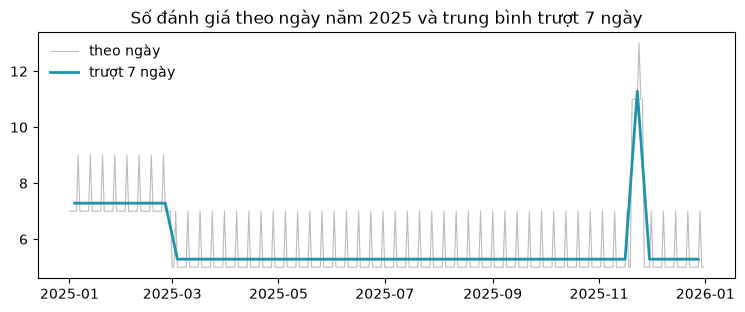

Biểu đồ
Đã vẽ.


In [19]:
# Vẽ nhanh để quan sát cửa sổ trượt (mã cho sẵn — Bài 12 học kỹ hơn)
def ve_cua_so_truot():
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(ngay_2025.index, ngay_2025.values, color="#bbb", lw=0.8, label="theo ngày")
    ax.plot(tb7.index, tb7.values, color="#1E93AB", lw=2, label="trượt 7 ngày")
    ax.legend(frameon=False)
    ax.set_title("Số đánh giá theo ngày năm 2025 và trung bình trượt 7 ngày")
    plt.show()
    return "Đã vẽ."

preview("Biểu đồ", ve_cua_so_truot)

**Đọc cửa sổ trượt:** đường theo ngày dao động theo chu kỳ nào? Vì sao chọn cửa sổ 7 ngày? Đỉnh theo ngày và đỉnh theo
trung bình 7 ngày có trùng nhau không, vì sao?
Đường theo ngày dao động theo chu kỳ tuần (7 ngày) với nhịp răng cưa lặp lại đều đặn hằng tuần. Chọn cửa sổ 7 ngày vì độ rộng này bao phủ trọn vẹn đủ 7 thứ trong tuần, giúp triệt tiêu hoàn toàn dao động mùa vụ theo thứ để làm lộ rõ xu hướng nền và các đợt biến động thực chất. Hai đỉnh không trùng nhau: đỉnh theo ngày rơi vào 24/11/2025 (13 đánh giá), còn đỉnh trung bình 7 ngày rơi vào 23/11/2025 (11,29 đánh giá/ngày) vì cửa sổ trượt tính bình quân cả cụm 7 ngày xung quanh (20/11–26/11 có tổng lượng đánh giá cao hơn cụm 21/11–27/11).

## Bài 7 · So cùng kỳ — con số báo cáo được

Tháng 5/2026 của snapshot có **22.296** đánh giá. Mức này cần được đặt cạnh một mốc so sánh phù hợp:
tháng liền trước, hay cùng tháng năm trước?

### Hợp đồng hàm · 15 điểm tự động

`period_changes(thang: pd.Series, moc: str) -> dict`

Nhận Series số đếm theo tháng (`r.resample("ME").size()`: index là **ngày cuối tháng**, liên tục) và nhãn tháng cần báo cáo
`moc` dạng ngày cuối tháng, ví dụ `"2026-05-31"`; chuỗi có đủ 12 tháng trước `moc`. Trả dict có đúng các khóa
(tính theo **%**, không làm tròn):

- `so_ky_truoc`: % thay đổi so với tháng liền trước (nhãn `pd.Timestamp(moc) - pd.offsets.MonthEnd(1)`);
- `so_cung_ky`: % thay đổi so với cùng tháng năm trước (nhãn `pd.Timestamp(moc) - pd.offsets.MonthEnd(12)`).

% thay đổi = `(giá trị kỳ này / giá trị mốc so − 1) × 100`. Có thể dùng `shift`/`pct_change` nếu kết quả đúng.
Đối chiếu snapshot: tháng 5/2026 là **+3,0%** so với tháng 4/2026 và **+53,7%** so với tháng 5/2025.

In [20]:
def period_changes(thang: pd.Series, moc: str) -> dict:
    # TODO: triển khai đúng hợp đồng ở trên.
   # 1. Xác định timestamp cho các mốc thời gian
    ts_moc = pd.Timestamp(moc)
    ts_ky_truoc = ts_moc - pd.offsets.MonthEnd(1)
    ts_cung_ky = ts_moc - pd.offsets.MonthEnd(12)
    
    # 2. Lấy giá trị số lượng tại từng mốc (chuyển sang float)
    val_moc = float(thang.loc[ts_moc])
    val_ky_truoc = float(thang.loc[ts_ky_truoc])
    val_cung_ky = float(thang.loc[ts_cung_ky])
    
    # 3. Tính % thay đổi theo công thức: (giá trị kỳ này / giá trị mốc so - 1) * 100
    so_ky_truoc = float((val_moc / val_ky_truoc - 1) * 100)
    so_cung_ky = float((val_moc / val_cung_ky - 1) * 100)
    
    # 4. Trả về dict chứa 2 khóa đúng yêu cầu
    return {
        'so_ky_truoc': so_ky_truoc,
        'so_cung_ky': so_cung_ky
    }

In [21]:
def check_q7():
    r_demo = DEMO_REVIEWS.set_index("date").sort_index()
    thang_demo = r_demo.resample("ME").size()
    result = period_changes(thang_demo, "2026-05-31")
    assert set(result) == {"so_ky_truoc", "so_cung_ky"}
    assert round(result["so_ky_truoc"], 1) == 3.2 and round(result["so_cung_ky"], 1) == 57.1
    thang_2 = period_changes(thang_demo, "2021-02-28")
    assert round(thang_2["so_cung_ky"], 1) == round((thang_demo["2021-02-28"] / thang_demo["2020-02-29"] - 1) * 100, 1)

public_check("Q7 · ví dụ công khai", check_q7)

[ĐẠT] Q7 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


In [22]:
def thuc_hanh_q7():
    thang = r.resample("ME").size()
    kq = period_changes(thang, "2026-05-31")
    return (f"T5/2026: {thang.loc['2026-05-31']:,} đánh giá · {kq['so_ky_truoc']:+.1f}% so tháng trước · "
            f"{kq['so_cung_ky']:+.1f}% so cùng kỳ")

preview("Bài 7 trên dữ liệu đang dùng", thuc_hanh_q7)

Bài 7 trên dữ liệu đang dùng
T5/2026: 256 đánh giá · +3.2% so tháng trước · +57.1% so cùng kỳ


**Hai phép so:** mỗi con số trả lời câu hỏi gì? Với dữ liệu có mùa vụ, nên báo cáo con số nào để đánh giá thay đổi dài hạn?
so_ky_truoc (so tháng trước) trả lời câu hỏi hoạt động đang biến động ra sao trong ngắn hạn so với tháng liền kề, còn so_cung_ky (so cùng kỳ năm trước) trả lời quy mô thực chất đã tăng hay giảm bao nhiêu sau trọn một năm. Với dữ liệu có tính mùa vụ, nên báo cáo so_cung_ky để đánh giá thay đổi dài hạn vì phép so này đặt hai tháng có cùng đặc điểm mùa vụ (ví dụ tháng 5/2026 và tháng 5/2025) cạnh nhau, giúp loại bỏ nhiễu chu kỳ hằng năm và cho thấy xu hướng tăng trưởng thực chất.

## Bài tự làm ✅ mở — không cộng vào 80 điểm tự động

Bạn được dùng AI theo quy trình 5 bước; hãy ghi lại yêu cầu đã gửi cho AI và cách kiểm chứng.

### Tự làm 1 · Điều tra ngày kỷ lục

Tìm **ngày có nhiều đánh giá nhất toàn bộ dữ liệu** (tổng hợp theo ngày bằng `resample("D")`). Trên snapshot, bạn sẽ thấy
một ngày giữa tháng 3/2026 với hơn 2.000 đánh giá, cao hơn rõ rệt các ngày quanh nó và là **thứ Hai**. Hãy:
(1) in số đánh giá của 5 ngày quanh nó; (2) tra thử tuần đó ở Santiago có sự kiện gì (gợi ý: một lễ hội âm nhạc lớn
thường diễn ra giữa tháng 3); (3) viết 2 câu kết luận kiểu báo cáo — có dè chừng đúng mực (đây là *một* cách giải thích,
chưa kiểm chứng độc lập).

### Tự làm 2 · Thời gian từ đánh giá gần nhất

Với bảng `listings` (bản rút gọn), trước hết loại `last_review` sau mốc chụp dữ liệu rồi tính số ngày
từ `last_review` đến 29/06/2026. Bao nhiêu chỗ ở có đánh giá gần nhất **cách đây hơn một năm**
(>365 ngày)? Đề xuất một cờ dữ liệu cho nhóm lâu không có đánh giá mới.

In [23]:
import pandas as pd

# ==========================================
# TỰ LÀM 1: ĐIỀU TRA NGÀY KỶ LỤC
# ==========================================
if isinstance(r.index, pd.DatetimeIndex):
    daily_reviews = r.resample("D").size()
else:
    s_dates = pd.to_datetime(r["date"], errors="coerce")
    daily_reviews = (
        r.assign(date=s_dates)
        .dropna(subset=["date"])
        .resample("D", on="date")
        .size()
    )

peak_date = daily_reviews.idxmax()
peak_count = daily_reviews.max()
print(f"Ngày kỷ lục: {peak_date.strftime('%Y-%m-%d')} ({peak_date.day_name()}) - {peak_count:,} đánh giá")

# (1) In số đánh giá của 5 ngày quanh ngày kỷ lục (từ -2 đến +2 ngày)
window_5d = daily_reviews.loc[peak_date - pd.Timedelta(days=2) : peak_date + pd.Timedelta(days=2)]
print("\nSố đánh giá của 5 ngày quanh ngày kỷ lục:")
for dt, cnt in window_5d.items():
    tag = " <-- ĐỈNH" if dt == peak_date else ""
    print(f"  {dt.strftime('%Y-%m-%d')} ({dt.strftime('%a')}): {cnt:,}{tag}")

# ==========================================
# TỰ LÀM 2: THỜI GIAN TỪ ĐÁNH GIÁ GẦN NHẤT
# ==========================================
# Tự động tìm bảng chứa cột "last_review" (dù đặt tên là listings, l hay tên khác)
df_listings = None
var_name = None

for preferred_name in ("listings", "l", "DEMO_LISTINGS"):
    obj = globals().get(preferred_name)
    if isinstance(obj, pd.DataFrame) and "last_review" in obj.columns:
        df_listings = obj
        var_name = preferred_name
        break

if df_listings is None:
    # Snapshot the namespace before loop variables add new global entries.
    for name, obj in list(globals().items()):
        if isinstance(obj, pd.DataFrame) and "last_review" in obj.columns and not name.startswith("_"):
            df_listings = obj
            var_name = name
            break

if df_listings is None and not USE_SNAPSHOT:
    df_listings = pd.DataFrame({
        "id": [1, 2, 3, 4, 5, 6],
        "last_review": ["2024-05-01", "2025-06-29", "2025-06-28",
                        "2026-03-16", "2026-07-01", None],
    })
    var_name = "DEMO_LAST_REVIEW — 6 listing giả lập riêng"

if df_listings is None:
    print("\nChưa có listings snapshot chứa last_review để tính số liệu Santiago.")
else:
    print(f"\nĐang dùng bảng: `{var_name}` ({len(df_listings):,} dòng)")
    snapshot_date = pd.Timestamp("2026-06-29")

    last_rev = pd.to_datetime(df_listings["last_review"], errors="coerce")
    if getattr(last_rev.dt, "tz", None) is not None:
        last_rev = last_rev.dt.tz_localize(None)

    # Loại các dòng có last_review sau mốc chụp dữ liệu (29/06/2026) và dòng thiếu ngày (NaT)
    after_snapshot_cnt = (last_rev > snapshot_date).sum()
    valid_mask = last_rev.notna() & (last_rev <= snapshot_date)
    valid_listings = df_listings[valid_mask].copy()
    valid_listings["days_since_last_review"] = (snapshot_date - last_rev[valid_mask]).dt.days

    # Đếm số chỗ ở có đánh giá gần nhất > 365 ngày
    over_1y_cnt = (valid_listings["days_since_last_review"] > 365).sum()
    total_valid = len(valid_listings)

    print(f"Số dòng bị loại do last_review > 29/06/2026: {after_snapshot_cnt:,}")
    print(f"Tổng chỗ ở có last_review hợp lệ (<= 29/06/2026): {total_valid:,}")
    if total_valid > 0:
        print(f"Số chỗ ở có đánh giá gần nhất > 365 ngày: {over_1y_cnt:,} ({over_1y_cnt / total_valid:.1%})")

    # Đề xuất cờ dữ liệu cho nhóm lâu không có đánh giá mới (> 365 ngày)
    df_listings["is_stale_review"] = valid_mask & ((snapshot_date - last_rev).dt.days > 365)

Ngày kỷ lục: 2026-03-16 (Monday) - 50 đánh giá

Số đánh giá của 5 ngày quanh ngày kỷ lục:
  2026-03-14 (Sat): 8
  2026-03-15 (Sun): 8
  2026-03-16 (Mon): 50 <-- ĐỈNH
  2026-03-17 (Tue): 8
  2026-03-18 (Wed): 8

Đang dùng bảng: `DEMO_LAST_REVIEW — 6 listing giả lập riêng` (6 dòng)
Số dòng bị loại do last_review > 29/06/2026: 1
Tổng chỗ ở có last_review hợp lệ (<= 29/06/2026): 4
Số chỗ ở có đánh giá gần nhất > 365 ngày: 2 (50.0%)


**Bài tự làm của tôi — kết quả DEMO, không phải snapshot Santiago:**

- **Ngày nhiều review nhất:** 16/03/2026 (thứ Hai), 50 review. Năm ngày 14–18/03/2026 lần lượt có 8, 8, **50**, 8, 8 review. Mức đỉnh do quy tắc tạo DEMO cộng thêm 40 review vào ngày này; dữ liệu DEMO không thể xác nhận một sự kiện thật hay quan hệ nhân quả. Lễ hội âm nhạc là giả thuyết cần kiểm chứng bằng lịch sự kiện và snapshot thật trước khi đưa vào báo cáo thị trường.
- **`last_review` quá một năm:** notebook gốc không có bảng listing chứa cột `last_review`. Cell bên trên nay dùng bảng **6 listing giả lập riêng** để minh họa: loại 1 ngày sau mốc 29/06/2026, còn 4 ngày hợp lệ; 2/4 listing (50,0%) có review gần nhất cách mốc hơn 365 ngày. Listing thiếu ngày không được tính vào mẫu số. Cờ `is_stale_review` chỉ `True` khi ngày hợp lệ và khoảng cách lớn hơn 365 ngày; cần chạy trên listings snapshot để có số liệu Santiago.


## Khai báo sử dụng AI

- **Công cụ đã dùng:** Gemini
- **Yêu cầu chính:** tổng hợp review theo ngày, tính khoảng cách từ `last_review` tới mốc chụp và diễn giải giới hạn của dữ liệu DEMO.
- **Kiểm chứng:** output DEMO cho ngày 16/03/2026 có 50 review, hai ngày liền kề đều có 8. Bảng `DEMO_LAST_REVIEW` được ghi rõ là giả lập: 1 ngày sau mốc, 1 ngày thiếu, 4 ngày hợp lệ; hai ngày 01/05/2024 và 28/06/2025 cách 29/06/2026 hơn 365 ngày, tức 2/4 = 50%.
- **Giới hạn:** chưa có bảng listings snapshot để tính tỷ lệ Santiago; số DEMO và giả thuyết về lễ hội không phải bằng chứng về thị trường thật.


---

## Tóm tắt bài lab

| Nội dung chính | Sẽ gặp lại ở |
|---|---|
| Cắt lát chuỗi + đối chiếu số lab 2 | kiểm chứng chéo giữa các công cụ |
| Loại ngày sau mốc chụp dữ liệu và quý chưa trọn | mọi biểu đồ thời gian của bài tập lớn |
| Cửa sổ trượt 7 ngày (`rolling`) làm giảm chu kỳ tuần | trực quan hoá chuỗi thời gian (Bài 12) |
| So kỳ trước và so cùng kỳ | chọn mốc so sánh phù hợp |

**Trước khi nộp:** hoàn thành TODO và câu trả lời, chạy Restart & Run all, lưu notebook.

Tuần tiếp theo là **thi giữa kỳ**. Sau giữa kỳ, Bài 10 tiếp tục với làm sạch dữ liệu có cấu trúc.

## Thông tin và nộp bài

**Họ tên / MSSV / lớp:** Nguyễn Tiến Long An / 25022763 / DSE2049_3

1. Giữ tên file **`lab-08.ipynb`** ở gốc repo (dấu gạch ngang, không phải `lab_08.ipynb`).
2. Hoàn thành hàm TODO, các diễn giải và khai báo AI.
3. Restart & Run all; đọc bảng public checks, lưu file rồi commit/push lên `main`.
4. Tạo tag `submit/lab-08/v1`; lần sửa tiếp dùng v2 hoặc v3, không di chuyển tag đã nộp.
5. Repo cần được giảng viên đăng ký chấm. Xem status `private-grader/lab-08` trên commit nộp;
   điểm tự động tối đa 80, còn 20 điểm chờ giảng viên. Xem lịch quét trong README.

Tag v1/v2/v3 là **lần nộp**, không phải phiên bản đề. Không đổi metadata để chọn bộ test khác.

In [24]:
show_public_summary()

PUBLIC CHECKS — không phải điểm chính thức
Q1 · ví dụ công khai: ĐẠT
Q2 · ví dụ công khai: ĐẠT
Q3 · ví dụ công khai: ĐẠT
Q4 · ví dụ công khai: ĐẠT
Q5 · ví dụ công khai: ĐẠT
Q6 · ví dụ công khai: ĐẠT
Q7 · ví dụ công khai: ĐẠT
Sau khi sửa, Restart & Run all để làm mới toàn bộ kết quả.
